# Part I - Univariate Analysis

In [18]:
from pathlib import Path
import platform
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.titlesize': 12})
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')
project_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'data' / 'ChainStore.csv').is_file()), None)
if project_root is None:
    raise FileNotFoundError('Expected data/ChainStore.csv in this project.')

## 1. Dataset Overview

In [19]:
raw_data = pd.read_csv(project_root / 'data' / 'ChainStore.csv', sep=';',
                       dtype={'Postal Code': 'string'})
data = raw_data.copy()
numerical_variables = ['Sales', 'Profit', 'Quantity', 'Discount', 'Profit Ratio']
categorical_variables = ['Category', 'Sub-Category', 'Region', 'Segment', 'Ship Mode']
for variable in numerical_variables:
    # Python-backed strings make \s match Unicode whitespace, including nonbreaking spaces.
    cleaned = data[variable].astype('string[python]').str.replace(r'[$%,\s]', '', regex=True)
    data[variable] = pd.to_numeric(cleaned, errors='raise')
for variable in ['Order Date', 'Ship Date']:
    data[variable] = pd.to_datetime(data[variable], format='%d/%m/%Y', errors='raise')
print(f'Shape: {len(data):,} product lines, {data.shape[1]} columns')
display(data.head())
display(pd.DataFrame({'raw_dtype': raw_data.dtypes.astype(str),
                      'analysis_dtype': data.dtypes.astype(str),
                      'missing': data.isna().sum(),
                      'distinct_nonmissing': data.nunique()}))
print('Unique order IDs:', data['Order ID'].nunique())
print('Order IDs repeated across lines:', (data['Order ID'].value_counts() > 1).sum())
print('Exact duplicates beyond first occurrence:', raw_data.duplicated().sum())
display(raw_data.loc[raw_data.duplicated(keep=False)])
print('Nonpositive recorded Sales:', (data['Sales'] <= 0).sum())
print('Nonpositive quantities:', (data['Quantity'] <= 0).sum())
print('Discounts outside 0-100%:', (~data['Discount'].between(0, 100)).sum())
print('Ship dates preceding order dates:', (data['Ship Date'] < data['Order Date']).sum())
assert np.isfinite(data[numerical_variables].to_numpy(dtype=float)).all()

Shape: 9,994 product lines, 21 columns


,Category,City,Country/Region,Customer Name,Manufacturer,Order Date,Order ID,Postal Code,Product Name,Region,...,Ship Date,Ship Mode,State,Sub-Category,Discount,Number of Records,Profit,Profit Ratio,Quantity,Sales
0,Furniture,Henderson,United States,Claire Gute,Bush,2018-11-08,CA-2018-152156,42420,Bush Somerset Collection Bookcase,South,...,2018-11-11,Second Class,Kentucky,Bookcases,0,1,42,16,2,262
1,Furniture,Henderson,United States,Claire Gute,Hon,2018-11-08,CA-2018-152156,42420,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",South,...,2018-11-11,Second Class,Kentucky,Chairs,0,1,220,30,3,732
2,Office Supplies,Los Angeles,United States,Darrin Van Huff,Universal,2018-06-12,CA-2018-138688,90036,Self-Adhesive Address Labels for Typewriters b...,West,...,2018-06-16,Second Class,California,Labels,0,1,7,47,2,15
3,Furniture,Fort Lauderdale,United States,Sean O'Donnell,Bretford,2017-10-11,US-2017-108966,33311,Bretford CR4500 Series Slim Rectangular Table,South,...,2017-10-18,Standard Class,Florida,Tables,45,1,-383,-40,5,958
4,Office Supplies,Fort Lauderdale,United States,Sean O'Donnell,Eldon,2017-10-11,US-2017-108966,33311,Eldon Fold 'N Roll Cart System,South,...,2017-10-18,Standard Class,Florida,Storage,20,1,3,11,2,22


,raw_dtype,analysis_dtype,missing,distinct_nonmissing
Category,str,str,0,3
City,str,str,0,531
Country/Region,str,str,0,1
Customer Name,str,str,0,793
Manufacturer,str,str,0,183
Order Date,str,datetime64[us],0,1236
Order ID,str,str,0,5009
Postal Code,string,string,11,630
Product Name,str,str,0,1850
Region,str,str,0,4


Unique order IDs: 5009
Order IDs repeated across lines: 2471
Exact duplicates beyond first occurrence: 1


,Category,City,Country/Region,Customer Name,Manufacturer,Order Date,Order ID,Postal Code,Product Name,Region,...,Ship Date,Ship Mode,State,Sub-Category,Discount,Number of Records,Profit,Profit Ratio,Quantity,Sales
3405,Furniture,Columbus,United States,Laurel Beltran,Global,23/04/2016,US-2016-150119,43229,Global Leather Highback Executive Chair with P...,East,...,27/04/2016,Standard Class,Ohio,Chairs,30%,1,-$12,-4%,2,$281
3406,Furniture,Columbus,United States,Laurel Beltran,Global,23/04/2016,US-2016-150119,43229,Global Leather Highback Executive Chair with P...,East,...,27/04/2016,Standard Class,Ohio,Chairs,30%,1,-$12,-4%,2,$281


Nonpositive recorded Sales: 1
Nonpositive quantities: 0
Discounts outside 0-100%: 0
Ship dates preceding order dates: 0


In [20]:
def msds_describe(series):
    """Per-variable sample statistics with strict Tukey flags; missing values excluded."""
    values = series.dropna().astype(float)
    q1, q3 = values.quantile([0.25, 0.75], interpolation='linear')
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mode_count = int(values.value_counts().max())
    return pd.Series({
        'Total rows': len(series), 'Observed': len(values), 'Missing': int(series.isna().sum()),
        'Mean': values.mean(), 'Median': values.median(),
        'Mode(s)': ', '.join(f'{v:g}' for v in values.mode()) if mode_count > 1 else 'No repeated value',
        'Mode frequency': mode_count, 'Sample SD (ddof=1)': values.std(ddof=1),
        'Minimum': values.min(), 'Q1': q1, 'Q3': q3, 'Maximum': values.max(),
        'IQR': iqr, 'Range': values.max() - values.min(),
        'Lower IQR fence': lower, 'Upper IQR fence': upper,
        'Lower flags': int((values < lower).sum()), 'Upper flags': int((values > upper).sum()),
        'Flagged (%)': 100 * ((values < lower) | (values > upper)).mean(),
        'Sample skewness': values.skew()})


def msds_frequency(series):
    """Include every category and missing if present; percentage denominator is all lines."""
    table = series.value_counts(dropna=False).rename('Product lines').to_frame()
    table.index.name = series.name
    table['Percent of all lines'] = 100 * table['Product lines'] / len(series)
    return table


import json
import textwrap
from matplotlib.ticker import FuncFormatter, PercentFormatter, MaxNLocator
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

plt.rcParams.update({
    'figure.dpi': 100, 'savefig.dpi': 200, 'font.family': 'DejaVu Sans',
    'font.size': 16, 'axes.labelsize': 17, 'xtick.labelsize': 15,
    'ytick.labelsize': 15, 'axes.titleweight': 'bold',
    'text.color': '#193445', 'axes.labelcolor': '#193445',
    'xtick.color': '#526878', 'ytick.color': '#526878',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.spines.left': False, 'axes.edgecolor': '#cbd5dc',
    'text.parse_math': False, 'svg.fonttype': 'none',
    'figure.facecolor': 'white', 'axes.facecolor': 'white'})
INK, TEAL, GRAY, LOSS, GOLD = '#193445', '#167d9a', '#c3cfd7', '#bd5548', '#bd741c'
figure_directory = project_root / 'doc' / 'figures' / 'univariate'
figure_directory.mkdir(parents=True, exist_ok=True)
figure_manifest = {}
chart_audit = {}


def msds_canvas(title, subtitle, footnote, bounds=(0.10, 0.22, 0.78, 0.54)):
    fig = plt.figure(figsize=(16, 9))
    fig.text(0.075, 0.925, title, fontsize=28, fontweight='bold', va='top')
    fig.text(0.075, 0.852, subtitle, fontsize=16, color='#526878', va='top')
    note = f'Source: ChainStore.csv. {len(data):,} product lines. ' + footnote
    fig.text(0.075, 0.075, textwrap.fill(note, width=155),
             fontsize=11.5, color='#526878', va='top', linespacing=1.5)
    ax = fig.add_axes(bounds)
    ax.set_axisbelow(True)
    ax.grid(axis='y', color='#e8edf0', linewidth=0.8)
    ax.tick_params(axis='both', length=0, pad=10)
    return fig, ax


def msds_export(fig, key, title, displayed, note):
    """Save slide-sized PNG and editable-text SVG, then display in the notebook."""
    assert 0 <= displayed <= len(data)
    fig.savefig(figure_directory / f'{key}.png', dpi=200, facecolor='white')
    fig.savefig(figure_directory / f'{key}.svg', facecolor='white')
    figure_manifest[key] = {'title': title, 'rows_displayed': int(displayed),
                            'rows_total': len(data), 'note': note,
                            'png': f'{key}.png', 'svg': f'{key}.svg'}
    plt.show()
    plt.close(fig)


def msds_histogram(ax, values, bins, total, key, signed=False):
    """Bin heights are shares of ALL product lines, even in a focused view."""
    heights, edges, bars = ax.hist(values, bins=bins,
        weights=np.full(len(values), 100 / total), color=TEAL,
        edgecolor='white', linewidth=0.6)
    if signed:
        for left, bar in zip(edges[:-1], bars):
            bar.set_facecolor(LOSS if left < 0 else TEAL)
    np.testing.assert_allclose(heights.sum(), 100 * len(values) / total)
    chart_audit[key] = {'binned': len(values), 'total': total,
                        'height_sum': float(heights.sum())}
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True, min_n_ticks=3))
    ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.set_ylabel('Share of all product lines')
    return heights


def msds_signed_log1p(values):
    return np.sign(values) * np.log1p(np.abs(values))


def msds_signed_expm1(values):
    return np.sign(values) * np.expm1(np.abs(values))


def msds_money(value, decimals=0):
    sign = '-' if value < 0 else ''
    return f'{sign}${abs(value):,.{decimals}f}'


def msds_stat(fig, x, y, value, label, color=INK, size=35):
    fig.text(x, y, value, fontsize=size, fontweight='bold', color=color)
    fig.text(x, y - 0.055, label, fontsize=15, color='#526878', linespacing=1.45)


def msds_plot_sales(series):
    values = series.dropna().astype(float)
    median, mean = values.median(), values.mean()
    title = f'The average sale is {mean / median:.1f} times the median'
    note = ('All values retained, including the zero sale. Horizontal scale: ln(1 + Sales). '
            'Equal horizontal distances represent unequal dollar differences.')
    fig, ax = msds_canvas(title,
        'Most product lines have modest sales, while a few large lines pull the mean upward',
        note, bounds=(0.09, 0.23, 0.64, 0.53))
    bins = np.expm1(np.linspace(0, np.log1p(values.max()), 61))
    bins[-1] = values.max()
    msds_histogram(ax, values, bins, len(data), 'Sales')
    ax.set_xlim(0, values.max() * 1.1)
    ax.set_xscale('function', functions=(np.log1p, np.expm1))
    ticks = [0, 10, 100, 1000, 10000]
    ax.set_xticks(ticks, labels=[msds_money(v) for v in ticks])
    ax.set_xlabel('Sales per product line (USD, compressed scale)', labelpad=15)
    ax.axvline(median, color=INK, linestyle='--', linewidth=2)
    ax.axvline(mean, color=GOLD, linestyle='--', linewidth=2)
    ax.legend(handles=[Line2D([], [], color=INK, linestyle='--', label='Median'),
                       Line2D([], [], color=GOLD, linestyle='--', label='Mean')],
              frameon=False, loc='upper left', fontsize=14)
    msds_stat(fig, 0.79, 0.68, msds_money(median, 2), 'Median line sales')
    msds_stat(fig, 0.79, 0.49, msds_money(mean, 2), 'Mean line sales', GOLD)
    msds_stat(fig, 0.79, 0.30, msds_money(values.max()), 'Largest recorded line', size=29)
    msds_export(fig, '01_sales_distribution', title, len(values), note)


def msds_plot_profit(series):
    values = series.dropna().astype(float)
    low, high = values.quantile([0.05, 0.95])
    focused = values[values.between(low, high)]
    below, above = int((values < low).sum()), int((values > high).sum())
    zeros = int(values.eq(0).sum())
    loss_share = 100 * values.lt(0).mean()
    near_zero = 100 * values.between(-10, 10).mean()
    title = 'Nearly one in five product lines records a loss'
    note = (f'Focus: 5th-95th percentiles ({msds_money(low)} to {msds_money(high)}). '
            f'{len(focused):,} lines shown; {below:,} below and {above:,} above omitted only here. '
            f'All {zeros} recorded zeros are included. Full tails appear in the appendix.')
    fig, ax = msds_canvas(title,
        f'A {msds_money(values.median())} median profit sits close to break-even',
        note, bounds=(0.09, 0.23, 0.64, 0.53))
    bins = np.arange(np.floor(low / 5) * 5, np.ceil(high / 5) * 5 + 5, 5)
    msds_histogram(ax, focused, bins, len(data), 'Profit focus', signed=True)
    ax.set_xlim(bins[0], bins[-1])
    ax.set_xlabel('Profit per product line (USD, $5 bins)', labelpad=15)
    ax.axvline(0, color=INK, linestyle=':', linewidth=1.8)
    ax.axvline(values.median(), color=GOLD, linestyle='--', linewidth=2)
    ax.legend(handles=[Patch(color=LOSS, label='Loss'), Patch(color=TEAL, label='Zero or gain'),
                       Line2D([], [], color=GOLD, linestyle='--', label='Median')],
              frameon=False, loc='upper right', fontsize=14)
    msds_stat(fig, 0.79, 0.65, f'{loss_share:.1f}%', 'of all lines\nrecord a loss', LOSS)
    msds_stat(fig, 0.79, 0.39, f'{near_zero:.1f}%', 'of all lines have profit\nbetween -$10 and $10')
    chart_audit['Profit tails'] = {'below': below, 'focused': len(focused),
                                  'above': above, 'zero': zeros}
    msds_export(fig, '02_profit_near_zero', title, len(focused), note)


def msds_plot_quantity(series):
    values = series.dropna().astype(float)
    counts = values.value_counts().sort_index()
    shares = 100 * counts / len(data)
    title = 'Three units is the most common line quantity'
    five_share = 100 * values.between(1, 5).mean()
    fig, ax = msds_canvas(title,
        'The median and mode are both 3 units, with relatively few large quantities',
        'Every observed quantity is shown. These are quantities within product lines, not complete order sizes.')
    colors = [TEAL if q == 3 else '#78adbd' if q <= 5 else GRAY for q in counts.index]
    ax.bar(counts.index, shares, width=0.72, color=colors)
    ax.set_xticks(counts.index.astype(int))
    ax.set_xlim(0.4, 14.6)
    ax.set_ylim(0, shares.max() * 1.22)
    ax.set(xlabel='Units in a product line', ylabel='Share of all product lines')
    ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    for q, share in shares.items():
        ax.annotate(f'{share:.1f}%', (q, share), xytext=(0, 7),
                    textcoords='offset points', ha='center', fontsize=12.5)
    ax.text(0.66, 0.85, f'{five_share:.1f}%', transform=ax.transAxes,
            fontsize=35, fontweight='bold', color=TEAL)
    ax.text(0.66, 0.72, 'of lines contain 1 to 5 units',
            transform=ax.transAxes, fontsize=16, color='#526878')
    assert counts.sum() == len(values)
    msds_export(fig, '03_quantity', title, len(values), 'All observed integer quantities; percentages use all product lines.')


def msds_plot_discount(series):
    values = series.dropna().astype(float)
    counts = values.value_counts().sort_index()
    shares = 100 * counts / len(data)
    common_share = 100 * values.isin([0, 20]).mean()
    title = f'{common_share:.1f}% of lines use either 0% or 20% discount'
    fig, ax = msds_canvas(title,
        'Discounts concentrate at a few observed levels rather than forming a smooth distribution',
        'All observed rates are shown, equally spaced as distinct levels. This chart describes frequency and does not establish an effect on profit.')
    positions = np.arange(len(counts))
    ax.bar(positions, shares, width=0.68,
           color=[TEAL if v in (0, 20) else GRAY for v in counts.index])
    ax.set_xticks(positions, labels=[f'{v:g}%' for v in counts.index])
    ax.set_ylim(0, shares.max() * 1.22)
    ax.set(xlabel='Observed discount level', ylabel='Share of all product lines')
    ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    for x, share in zip(positions, shares):
        ax.annotate(f'{share:.1f}%', (x, share), xytext=(0, 8),
                    textcoords='offset points', ha='center', fontsize=13.5)
    assert counts.sum() == len(values)
    msds_export(fig, '04_discount', title, len(values), 'All observed discount levels; percentages use all product lines.')


def msds_plot_profit_ratio(series):
    values = series.dropna().astype(float)
    title = 'A 27% median line margin hides a long loss tail'
    note = ('Original rounded Profit Ratio, including the full -275% to 50% range. '
            'Histogram bins span 5 percentage points. The unweighted mean is not the overall business profit margin.')
    fig, ax = msds_canvas(title,
        'The negative tail pulls the unweighted mean down to 12.1%', note,
        bounds=(0.10, 0.22, 0.80, 0.54))
    bins = np.arange(np.floor(values.min() / 5) * 5,
                     np.ceil(values.max() / 5) * 5 + 5, 5)
    msds_histogram(ax, values, bins, len(data), 'Profit Ratio', signed=True)
    ax.set_xlim(bins[0], bins[-1])
    ax.set_xlabel('Recorded Profit Ratio (5 percentage point bins)', labelpad=15)
    ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.axvline(0, color=INK, linestyle=':', linewidth=1.5)
    ax.axvline(values.median(), color=INK, linestyle='--', linewidth=2)
    ax.axvline(values.mean(), color=GOLD, linestyle='--', linewidth=2)
    ax.legend(handles=[Line2D([], [], color=INK, linestyle='--', label=f'Median: {values.median():.0f}%'),
                       Line2D([], [], color=GOLD, linestyle='--', label=f'Mean: {values.mean():.1f}%')],
              frameon=False, loc='upper left', fontsize=17)
    ax.text(0.07, 0.53, 'Most margins are positive,\nbut some recorded losses\nexceed the line sales amount.',
            transform=ax.transAxes, fontsize=18, color='#526878', linespacing=1.7)
    msds_export(fig, '05_profit_ratio', title, len(values), note)


def msds_plot_categorical(series):
    table = msds_frequency(series)
    shares, counts = table['Percent of all lines'], table['Product lines']
    titles = {
        'Category': 'Office Supplies account for 60% of product lines',
        'Sub-Category': 'Binders are the most common product family',
        'Region': 'West and East account for 60.5% of product lines',
        'Segment': 'Consumer accounts for 52% of product lines',
        'Ship Mode': 'Six in ten product lines use Standard Class'}
    subtitles = {
        'Category': 'The number of lines measures product mix rather than financial contribution',
        'Sub-Category': 'Binders appear on 1,523 lines, compared with just 68 for Copiers',
        'Region': 'West leads at 32.0%, followed by East at 28.5%',
        'Segment': 'Consumer appears on 5,191 lines, compared with 3,020 for Corporate',
        'Ship Mode': 'Standard Class appears on 5,968 lines, while Same Day appears on 543'}
    keys = {'Category': '06_category', 'Sub-Category': '07_subcategory',
            'Region': '08_region', 'Segment': '09_segment', 'Ship Mode': '10_ship_mode'}
    many = len(table) > 8
    bounds = (0.22, 0.20, 0.62, 0.59) if many else (0.23, 0.27, 0.57, 0.44)
    note = ('Every level is shown. Labels give share of all lines and line count. '
            'These are product-line shares, not revenue, customer, or unique-order shares.')
    fig, ax = msds_canvas(titles[series.name], subtitles[series.name], note, bounds=bounds)
    positions = np.arange(len(table))
    colors = [TEAL if i == 0 or (series.name == 'Region' and label == 'East')
              else GOLD if many and i == len(table) - 1 else GRAY
              for i, label in enumerate(table.index)]
    ax.barh(positions, shares, height=0.65 if many else 0.52, color=colors)
    ax.set_yticks(positions, labels=table.index.astype(str), fontsize=13.5 if many else 18)
    ax.invert_yaxis()
    ax.grid(False)
    ax.grid(axis='x', color='#e8edf0', linewidth=0.8)
    ax.set_xlim(0, shares.max() * (1.28 if many else 1.20))
    ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.set_xlabel('Share of all product lines', labelpad=15)
    for y, share, count in zip(positions, shares, counts):
        ax.text(share + shares.max() * 0.018, y, f'{share:.1f}% ({count:,})',
                va='center', fontsize=12.5 if many else 17,
                color=INK if y == 0 else '#526878')
    assert counts.sum() == len(series)
    msds_export(fig, keys[series.name], titles[series.name], len(series), note)


def msds_plot_sales_concentration(series):
    values = series.dropna().astype(float).sort_values(ascending=False).to_numpy()
    n = len(values)
    rank_share = np.arange(n + 1) / n * 100
    amount_share = np.r_[0, np.cumsum(values)] / values.sum() * 100
    top_n = int(np.ceil(0.10 * n))
    x, y = rank_share[top_n], amount_share[top_n]
    title = f'The largest 10% of lines account for {y:.0f}% of Sales'
    note = (f'All lines ranked by Sales, largest first. The highlighted group contains {top_n:,} lines '
            f'({x:.2f}% of lines) and accounts for {y:.1f}% of total recorded Sales. This is a univariate concentration measure.')
    fig, ax = msds_canvas(title,
        'A small part of the line volume represents a large part of the recorded sales amount', note)
    ax.fill_between(rank_share, rank_share, amount_share, color=TEAL, alpha=0.07)
    ax.plot(rank_share, amount_share, color=TEAL, linewidth=3.5)
    ax.plot([0, 100], [0, 100], color='#9aaebc', linestyle='--', linewidth=1.5)
    ax.plot([x, x], [0, y], color=GOLD, linestyle=':', linewidth=1.7)
    ax.plot([0, x], [y, y], color=GOLD, linestyle=':', linewidth=1.7)
    ax.scatter([x], [y], s=100, color=GOLD, zorder=5)
    ax.annotate(f'{y:.1f}% of Sales\nfrom the largest 10% of lines', (x, y),
                xytext=(35, -5), textcoords='offset points', fontsize=19,
                color=INK, va='top', linespacing=1.6)
    ax.set(xlim=(0, 100), ylim=(0, 104),
           xlabel='Share of product lines, ranked from largest Sales to smallest',
           ylabel='Cumulative share of total Sales')
    ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    np.testing.assert_allclose(amount_share[-1], 100)
    assert np.all(np.diff(amount_share) >= 0)
    chart_audit['Sales concentration'] = {'top_n': top_n, 'line_share': float(x),
                                         'sales_share': float(y)}
    msds_export(fig, '11_sales_concentration', title, n, note)


def msds_plot_business_profile(frame):
    variables = ['Category', 'Segment', 'Ship Mode', 'Region']
    tables = [msds_frequency(frame[v]) for v in variables]
    labels = [f'{v}: {t.index[0]}' for v, t in zip(variables, tables)]
    shares = [t['Percent of all lines'].iloc[0] for t in tables]
    title = 'Product-line profile'
    note = ('Each row shows the most frequent level in one variable. The gray remainder contains all other levels of that variable. '
            'Full categorical breakdowns appear in the notebook. Rows describe separate distributions.')
    fig, ax = msds_canvas(title,
        f'{len(frame):,} product lines across {frame["Order ID"].nunique():,} orders',
        note, bounds=(0.32, 0.27, 0.56, 0.45))
    positions = np.arange(len(variables))
    ax.barh(positions, np.full(4, 100), color='#e8edf0', height=0.50)
    ax.barh(positions, shares, color=TEAL, height=0.50)
    ax.set_yticks(positions, labels=labels, fontsize=17)
    ax.invert_yaxis()
    ax.grid(False)
    ax.set_xlim(0, 100)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.set_xlabel('Share of all product lines', labelpad=15)
    for y, share in zip(positions, shares):
        ax.text(share + 2, y, f'{share:.1f}%', va='center', fontsize=20,
                fontweight='bold', color=INK)
    msds_export(fig, '12_business_profile', title, len(frame), note)


def msds_plot_profit_full(series):
    values = series.dropna().astype(float)
    title = 'Both large losses and large gains remain in the analysis'
    extent = values.abs().max()
    bins = msds_signed_expm1(np.linspace(-np.log1p(extent), np.log1p(extent), 81))
    bins[0], bins[40], bins[-1] = -extent, 0, extent
    note = ('All Profit values, including zero. Horizontal scale: sign(Profit) × ln(1 + abs(Profit)). '
            'Bins have equal widths on this transformed scale and unequal widths in dollars.')
    fig, ax = msds_canvas(title,
        f'The complete range spans {msds_money(values.min())} to {msds_money(values.max())}', note)
    msds_histogram(ax, values, bins, len(data), 'Profit full', signed=True)
    ax.set_xlim(-extent * 1.2, extent * 1.2)
    ax.set_xscale('function', functions=(msds_signed_log1p, msds_signed_expm1))
    ticks = [-1000, -100, -10, 0, 10, 100, 1000]
    ax.set_xticks(ticks, labels=[msds_money(v) for v in ticks])
    ax.axvline(0, color=INK, linestyle=':', linewidth=1.5)
    ax.set_xlabel('Profit per product line (USD, signed log1p scale)', labelpad=15)
    ax.legend(handles=[Patch(color=LOSS, label='Loss'), Patch(color=TEAL, label='Zero or gain')],
              loc='upper left', frameon=False, fontsize=16)
    msds_export(fig, 'appendix_01_profit_full_range', title, len(values), note)


def msds_plot_boxplots(frame):
    title = 'Quartiles and extremes complement the headline findings'
    note = ('All observed values. Tukey whiskers and outlier flags use original units before any axis rescaling. '
            'Each row has its own labeled scale; lengths cannot be compared across rows.')
    fig, unused = msds_canvas(title,
        'Full-range IQR box plots provide technical detail for all five numerical variables', note)
    unused.remove()
    for i, variable in enumerate(numerical_variables):
        values = frame[variable].dropna().astype(float)
        ax = fig.add_axes((0.20, 0.68 - i * 0.119, 0.68, 0.067))
        ax.boxplot(values, vert=False, whis=1.5, widths=0.45, patch_artist=True,
                   boxprops={'facecolor': '#d9eaf0', 'edgecolor': TEAL},
                   medianprops={'color': GOLD, 'linewidth': 2},
                   flierprops={'marker': '.', 'markersize': 2.5, 'alpha': 0.30,
                               'markeredgecolor': '#526878'})
        ax.set_yticks([])
        ax.tick_params(axis='x', labelsize=11, length=0)
        ax.text(-0.025, 0.50, variable, transform=ax.transAxes, ha='right',
                va='center', fontsize=15, fontweight='bold')
        if variable == 'Sales':
            ax.set_xlim(0, values.max() * 1.2)
            ax.set_xscale('function', functions=(np.log1p, np.expm1))
            ticks = [0, 10, 100, 1000, 10000]
            ax.set_xticks(ticks, labels=[msds_money(v) for v in ticks])
            ax.text(1.02, 0.5, 'USD\nlog1p', transform=ax.transAxes, va='center', fontsize=11)
        elif variable == 'Profit':
            extent = values.abs().max()
            ax.set_xlim(-extent * 1.2, extent * 1.2)
            ax.set_xscale('function', functions=(msds_signed_log1p, msds_signed_expm1))
            ticks = [-1000, -100, -10, 0, 10, 100, 1000]
            ax.set_xticks(ticks, labels=[msds_money(v) for v in ticks])
            ax.text(1.02, 0.5, 'USD\nsigned log1p', transform=ax.transAxes, va='center', fontsize=11)
        elif variable in ['Discount', 'Profit Ratio']:
            ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
            ax.text(1.02, 0.5, '%\nlinear', transform=ax.transAxes, va='center', fontsize=11)
        else:
            ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=7))
            ax.text(1.02, 0.5, 'units\nlinear', transform=ax.transAxes, va='center', fontsize=11)
        ax.spines['bottom'].set_color('#d8e0e5')
    msds_export(fig, 'appendix_02_full_range_boxplots', title, len(frame), note)


numerical_summary = pd.DataFrame({v: msds_describe(data[v]) for v in numerical_variables})
frequency_tables = {v: msds_frequency(data[v]) for v in categorical_variables}

## 2. Numerical Variables Analysis

### 2.1. Sales

Sales records the monetary amount of one product line in USD. It is numerical, supplied in whole dollars.


,Value
Total rows,9994
Observed,9994
Missing,0
Mean,229.873
Median,54.500
Mode(s),13
Mode frequency,200
Sample SD (ddof=1),623.249
Minimum,0.000
Q1,17.000


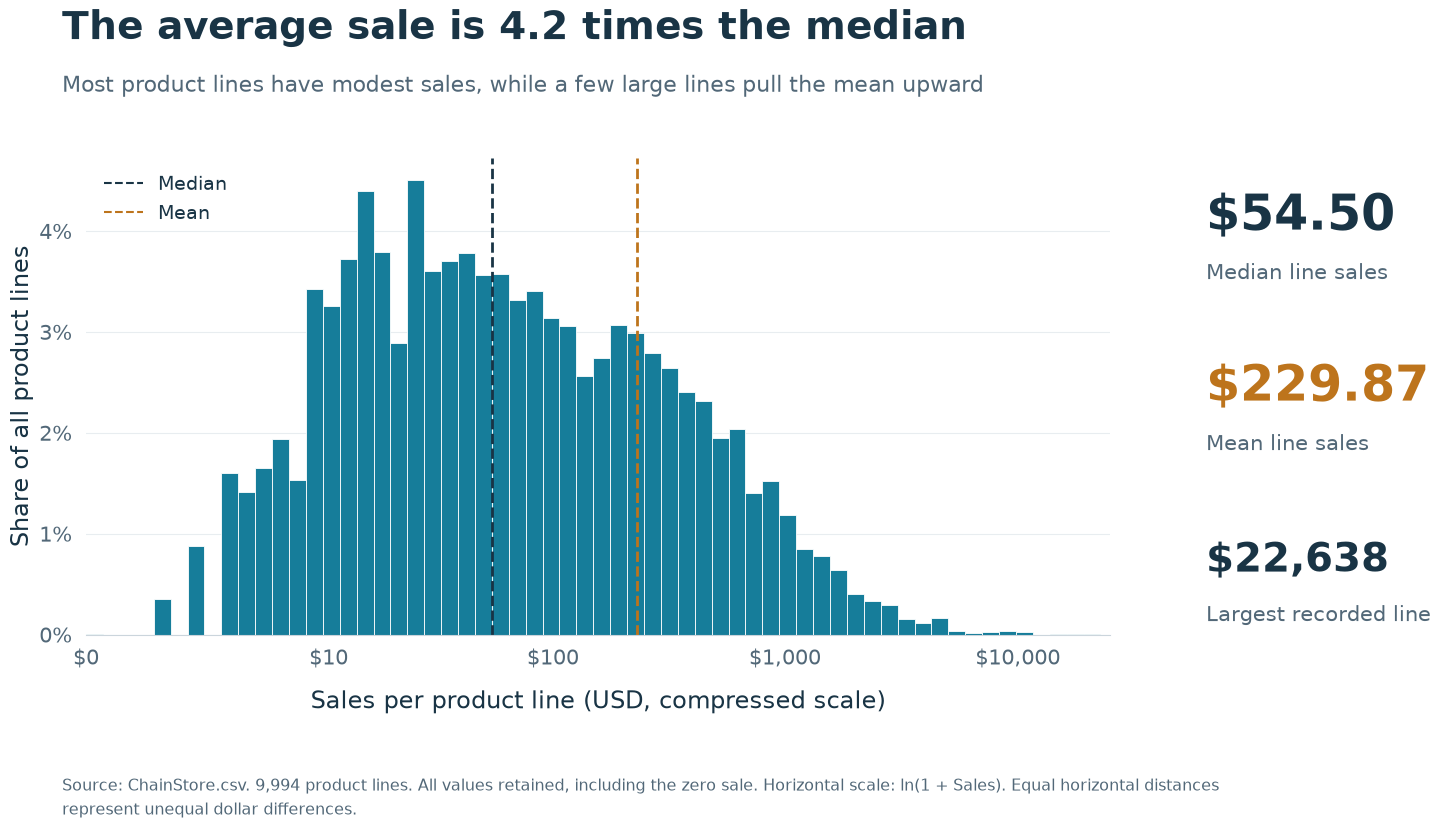

In [21]:
display(numerical_summary[['Sales']].rename(columns={'Sales': 'Value'}))
msds_plot_sales(data['Sales'])

### 2.2. Profit

Profit records the profit or loss of one product line in USD. It is numerical, supplied in whole dollars. Negative values represent recorded losses.

,Value
Total rows,9994
Observed,9994
Missing,0
Mean,28.652
Median,9.000
Mode(s),4
Mode frequency,436
Sample SD (ddof=1),234.256
Minimum,"-6,600.000"
Q1,2.000


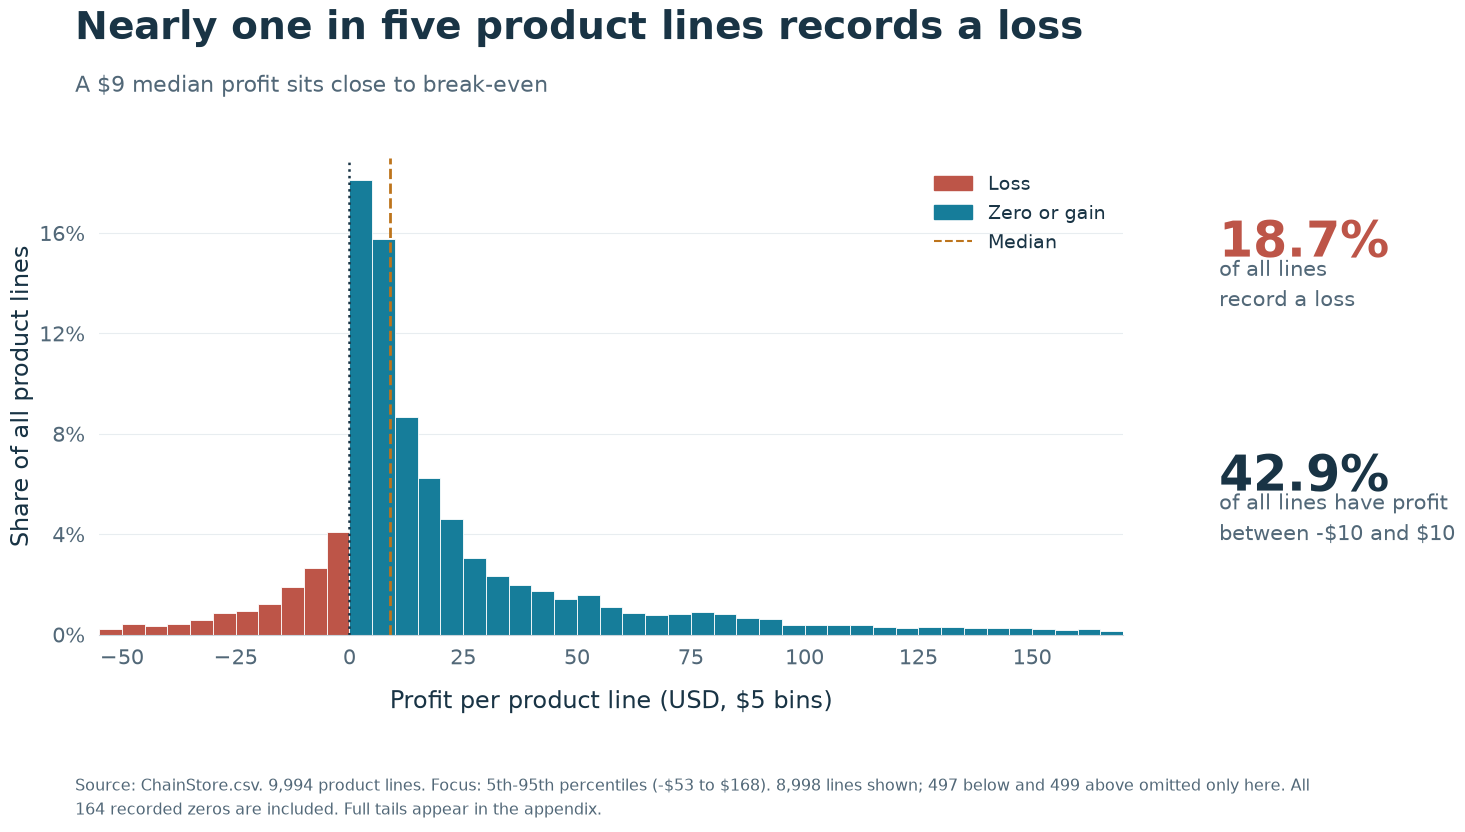

In [22]:
display(numerical_summary[['Profit']].rename(columns={'Profit': 'Value'}))
msds_plot_profit(data['Profit'])

### 2.3. Quantity

Quantity counts units in one product line. It is numerical and discrete because the observed counts are integers.

,Value
Total rows,9994
Observed,9994
Missing,0
Mean,3.790
Median,3.000
Mode(s),3
Mode frequency,2409
Sample SD (ddof=1),2.225
Minimum,1.000
Q1,2.000


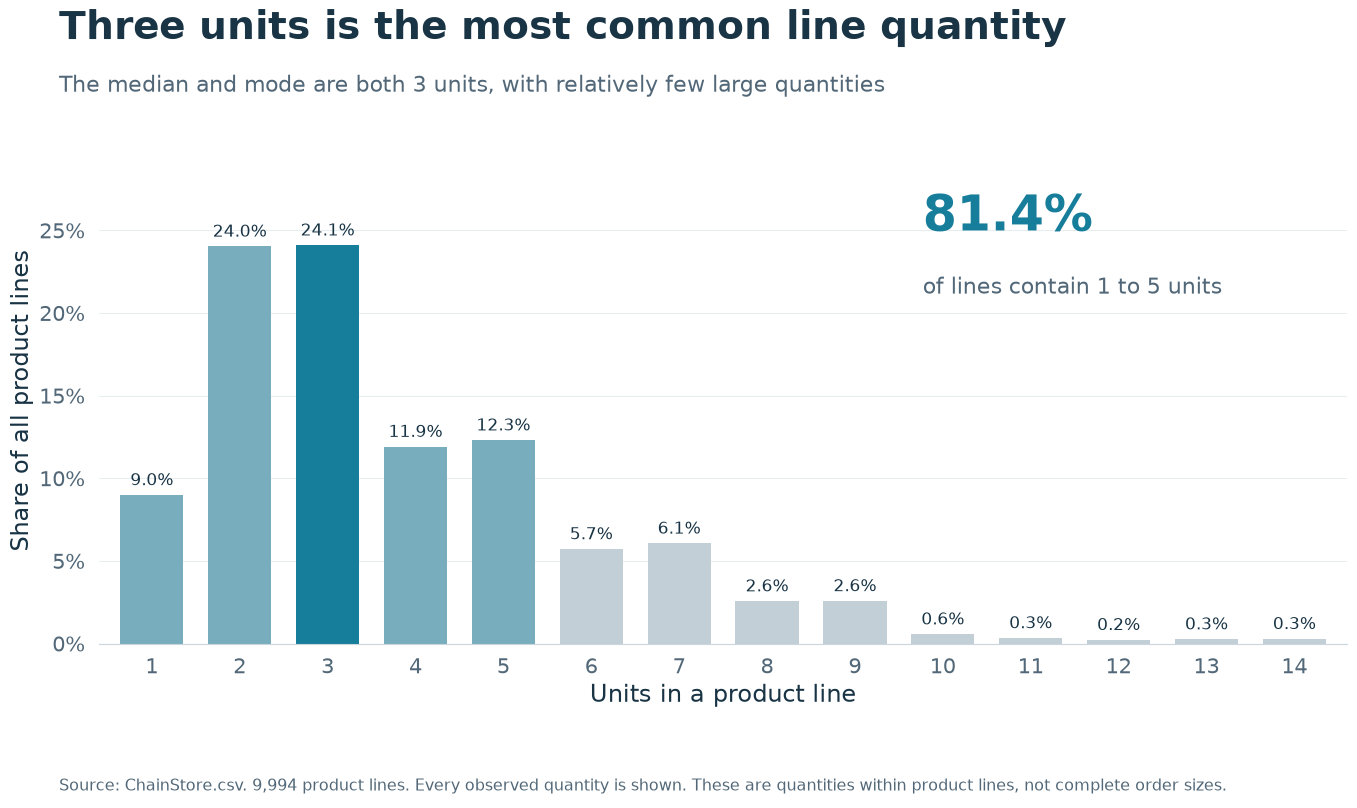

In [23]:
display(numerical_summary[['Quantity']].rename(columns={'Quantity': 'Value'}))
msds_plot_quantity(data['Quantity'])

### 2.4. Discount

Discount is a numerical price-reduction rate supplied in whole percent. Its observed support consists of discrete rates, and differences in rates remain meaningful.

,Value
Total rows,9994
Observed,9994
Missing,0
Mean,15.620
Median,20.000
Mode(s),0
Mode frequency,4798
Sample SD (ddof=1),20.645
Minimum,0.000
Q1,0.000


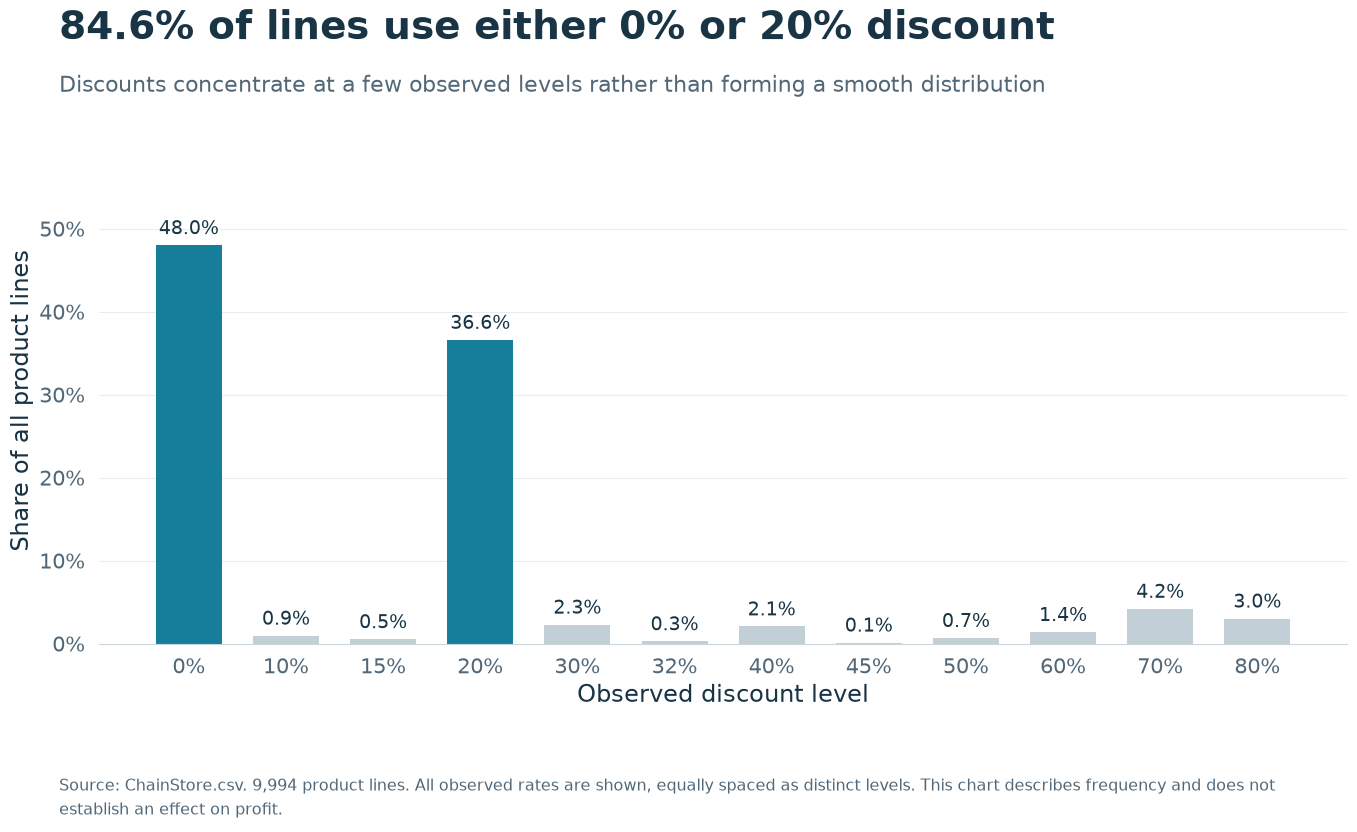

In [24]:
display(numerical_summary[['Discount']].rename(columns={'Discount': 'Value'}))
msds_plot_discount(data['Discount'])

### 2.5. Profit Ratio

Profit Ratio is the supplied line-level profitability rate, conceptually continuous but recorded in whole percent. It is retained rather than reconstructed from rounded monetary fields.

,Value
Total rows,9994
Observed,9994
Missing,0
Mean,12.053
Median,27.000
Mode(s),48
Mode frequency,509
Sample SD (ddof=1),46.692
Minimum,-275.000
Q1,7.000


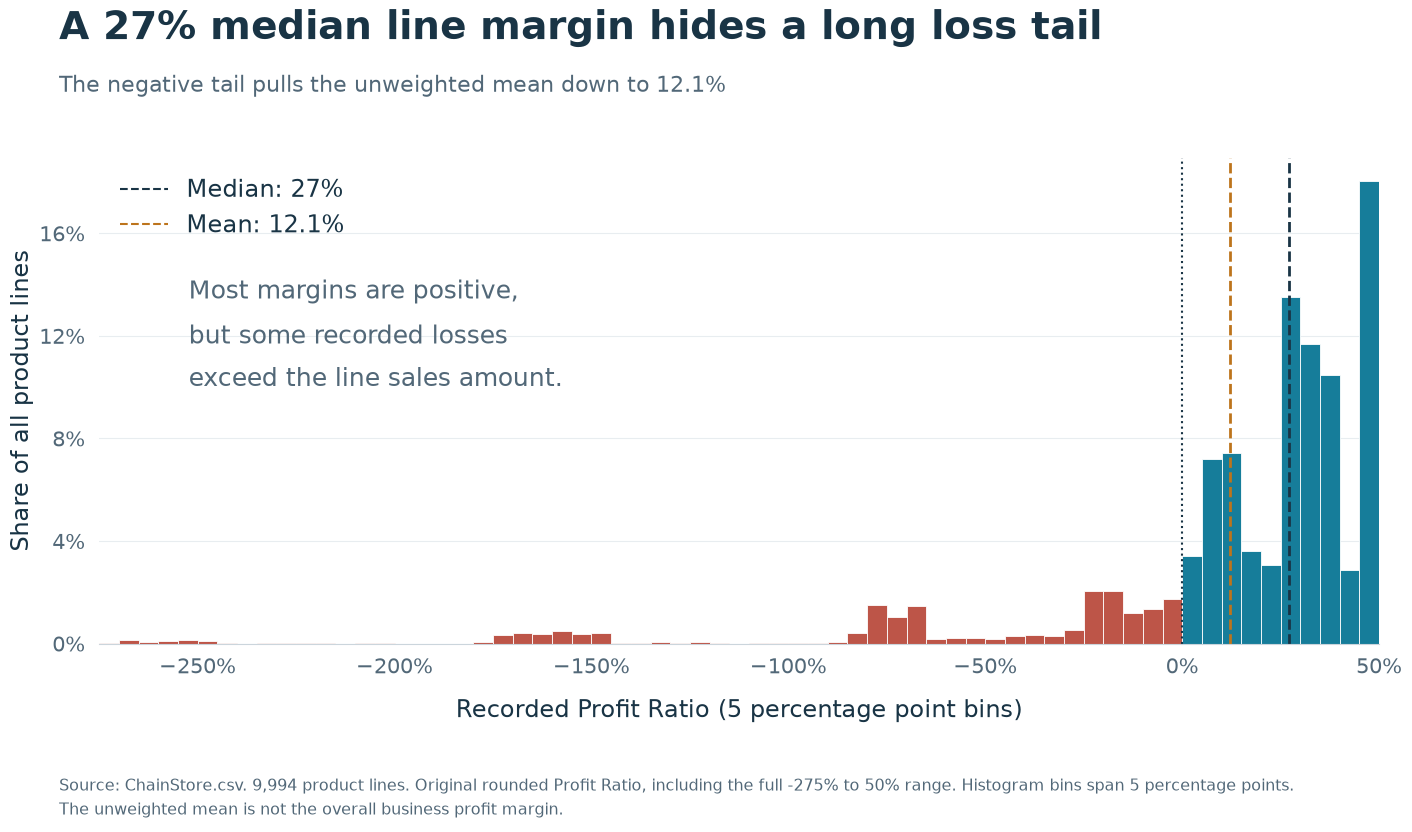

In [25]:
display(numerical_summary[['Profit Ratio']].rename(columns={'Profit Ratio': 'Value'}))
msds_plot_profit_ratio(data['Profit Ratio'])

## 3. Categorical Variables Analysis


### 3.1. Category

Category identifies the broad product family. These are unordered labels rather than measurements. We examine the representation of the broad product families.

,Product lines,Percent of all lines
Category,,
Office Supplies,6026,60.296
Furniture,2121,21.223
Technology,1847,18.481


Distinct nonmissing categories: 3
Missing values: 0
Mode(s): ['Office Supplies']


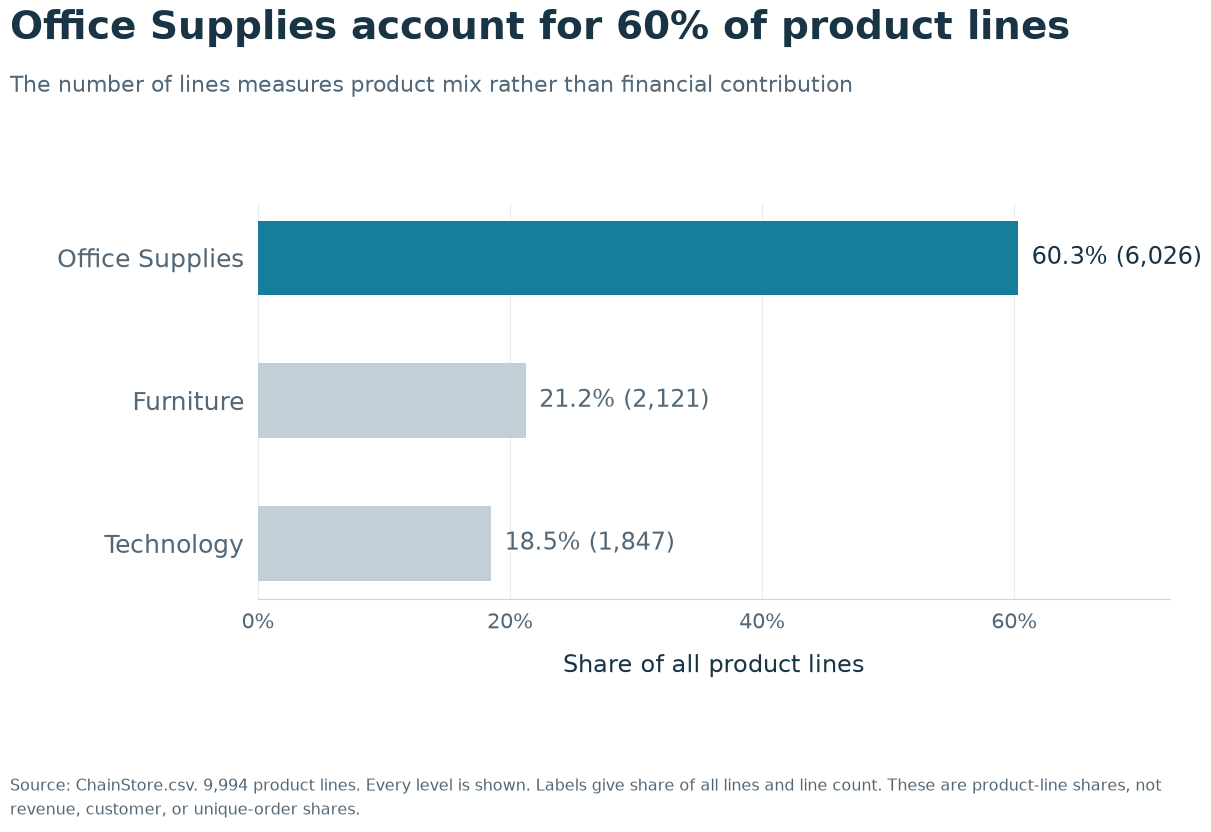

In [26]:
display(frequency_tables['Category'])
print('Distinct nonmissing categories:', data['Category'].nunique())
print('Missing values:', data['Category'].isna().sum())
print('Mode(s):', data['Category'].mode().tolist())
msds_plot_categorical(data['Category'])

### 3.2. Sub-Category

Sub-Category identifies a more detailed product family. Labels are nominal, without a natural numerical order. We examine which detailed families are most and least represented.

,Product lines,Percent of all lines
Sub-Category,,
Binders,1523,15.239
Paper,1370,13.708
Furnishings,957,9.576
Phones,889,8.895
Storage,846,8.465
Art,796,7.965
Accessories,775,7.755
Chairs,617,6.174
Appliances,466,4.663


Distinct nonmissing categories: 17
Missing values: 0
Mode(s): ['Binders']


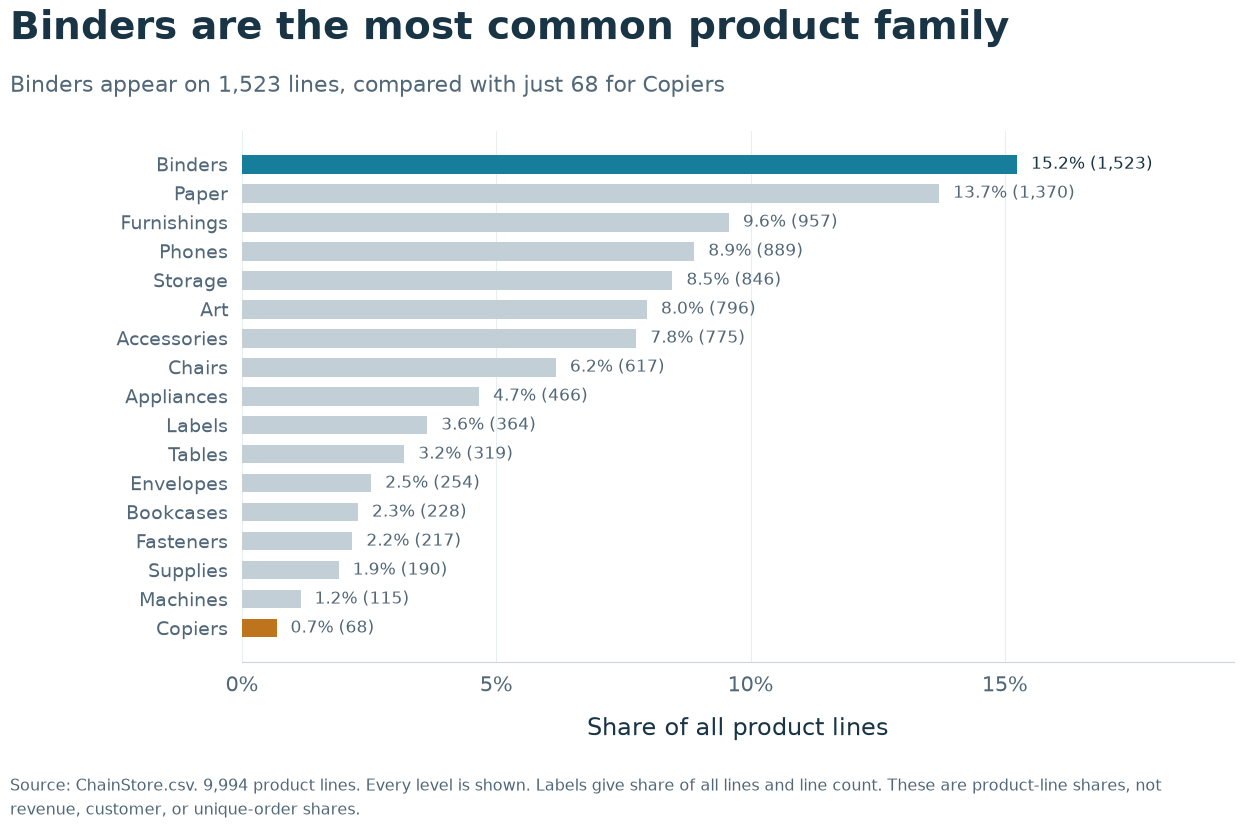

In [27]:
display(frequency_tables['Sub-Category'])
print('Distinct nonmissing categories:', data['Sub-Category'].nunique())
print('Missing values:', data['Sub-Category'].isna().sum())
print('Mode(s):', data['Sub-Category'].mode().tolist())
msds_plot_categorical(data['Sub-Category'])

### 3.3. Region

Region identifies a geographic grouping. These labels are nominal. We examine the distribution of product lines across regions.

,Product lines,Percent of all lines
Region,,
West,3203,32.049
East,2848,28.497
Central,2323,23.244
South,1620,16.210


Distinct nonmissing categories: 4
Missing values: 0
Mode(s): ['West']


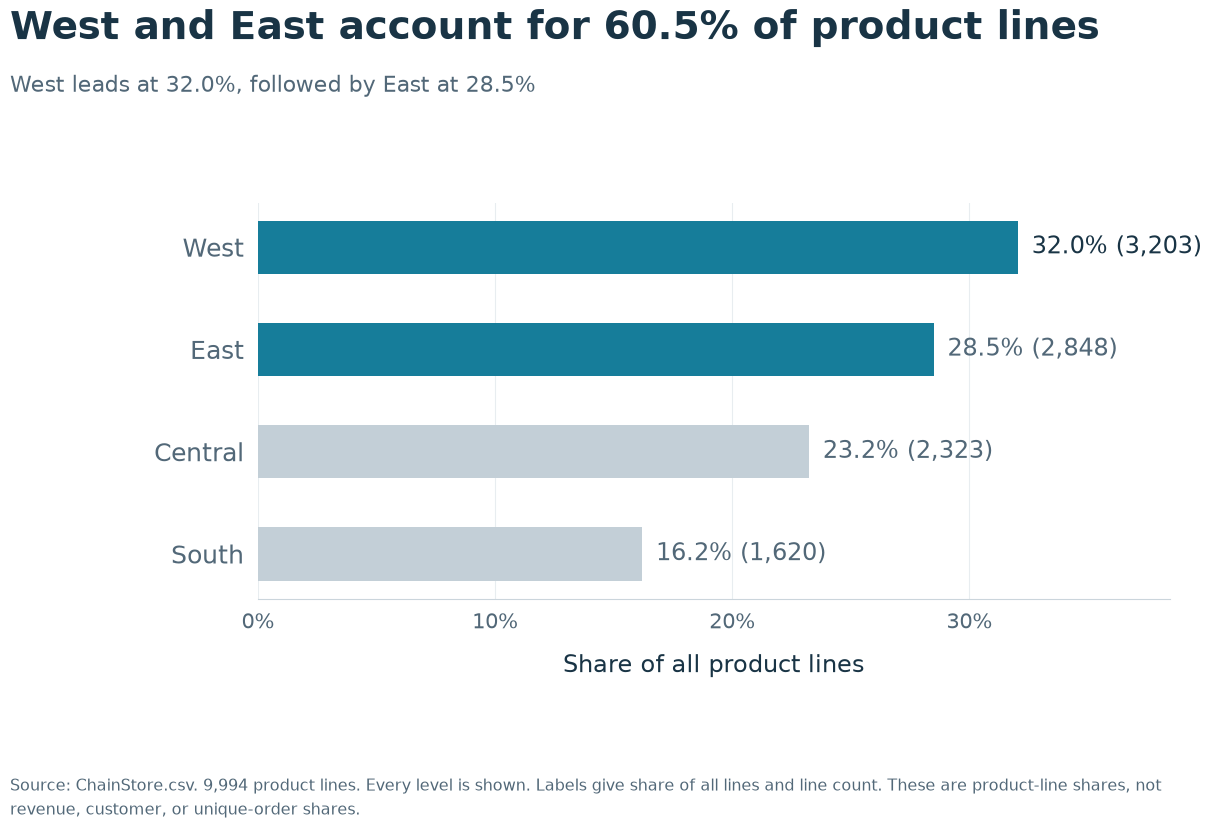

In [28]:
display(frequency_tables['Region'])
print('Distinct nonmissing categories:', data['Region'].nunique())
print('Missing values:', data['Region'].isna().sum())
print('Mode(s):', data['Region'].mode().tolist())
msds_plot_categorical(data['Region'])

### 3.4. Segment

Segment identifies a customer segment label. It is nominal, without an intrinsic numerical rank. We examine product-line composition by segment rather than counting unique customers.

,Product lines,Percent of all lines
Segment,,
Consumer,5191,51.941
Corporate,3020,30.218
Home Office,1783,17.841


Distinct nonmissing categories: 3
Missing values: 0
Mode(s): ['Consumer']


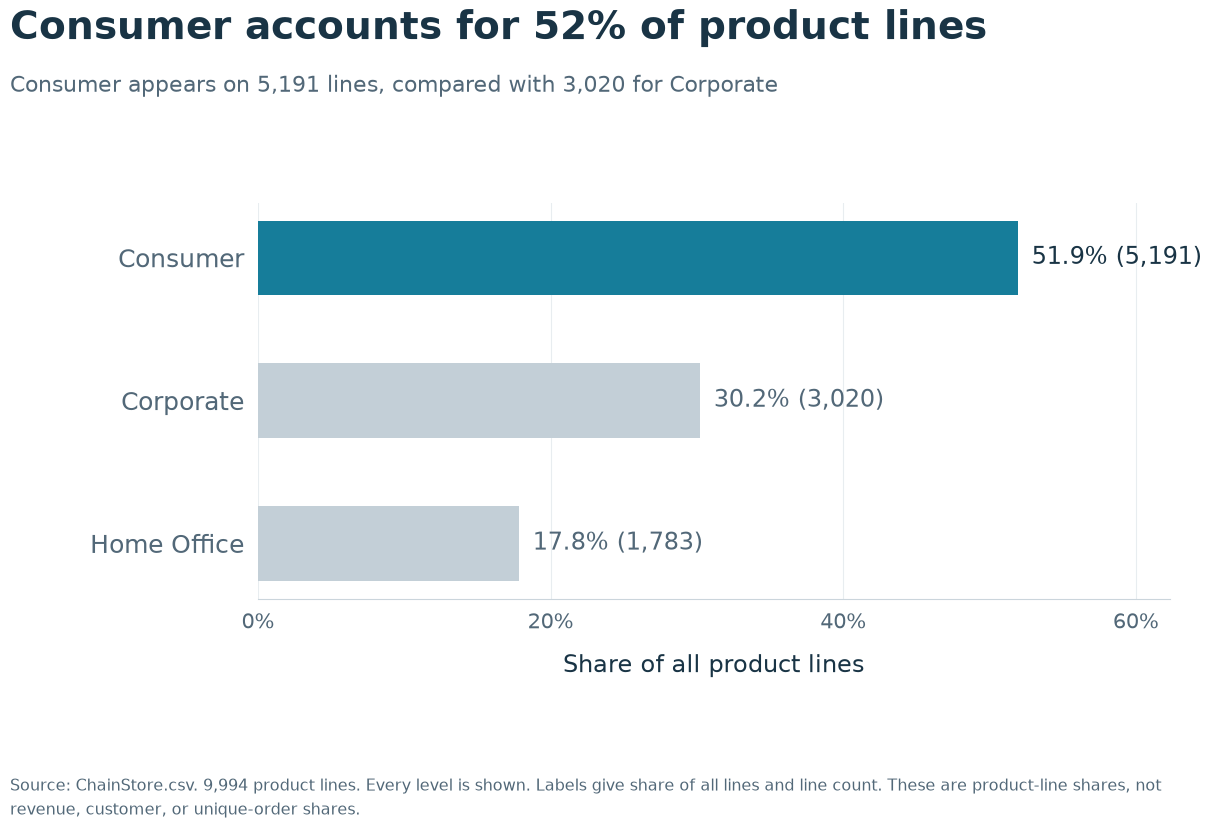

In [29]:
display(frequency_tables['Segment'])
print('Distinct nonmissing categories:', data['Segment'].nunique())
print('Missing values:', data['Segment'].isna().sum())
print('Mode(s):', data['Segment'].mode().tolist())
msds_plot_categorical(data['Segment'])

### 3.5. Ship Mode

Ship Mode identifies the recorded shipping service. It is treated as nominal because we do not impose a numerical rank on service labels or infer actual delivery duration. We examine the relative frequency of services.

,Product lines,Percent of all lines
Ship Mode,,
Standard Class,5968,59.716
Second Class,1945,19.462
First Class,1538,15.389
Same Day,543,5.433


Distinct nonmissing categories: 4
Missing values: 0
Mode(s): ['Standard Class']


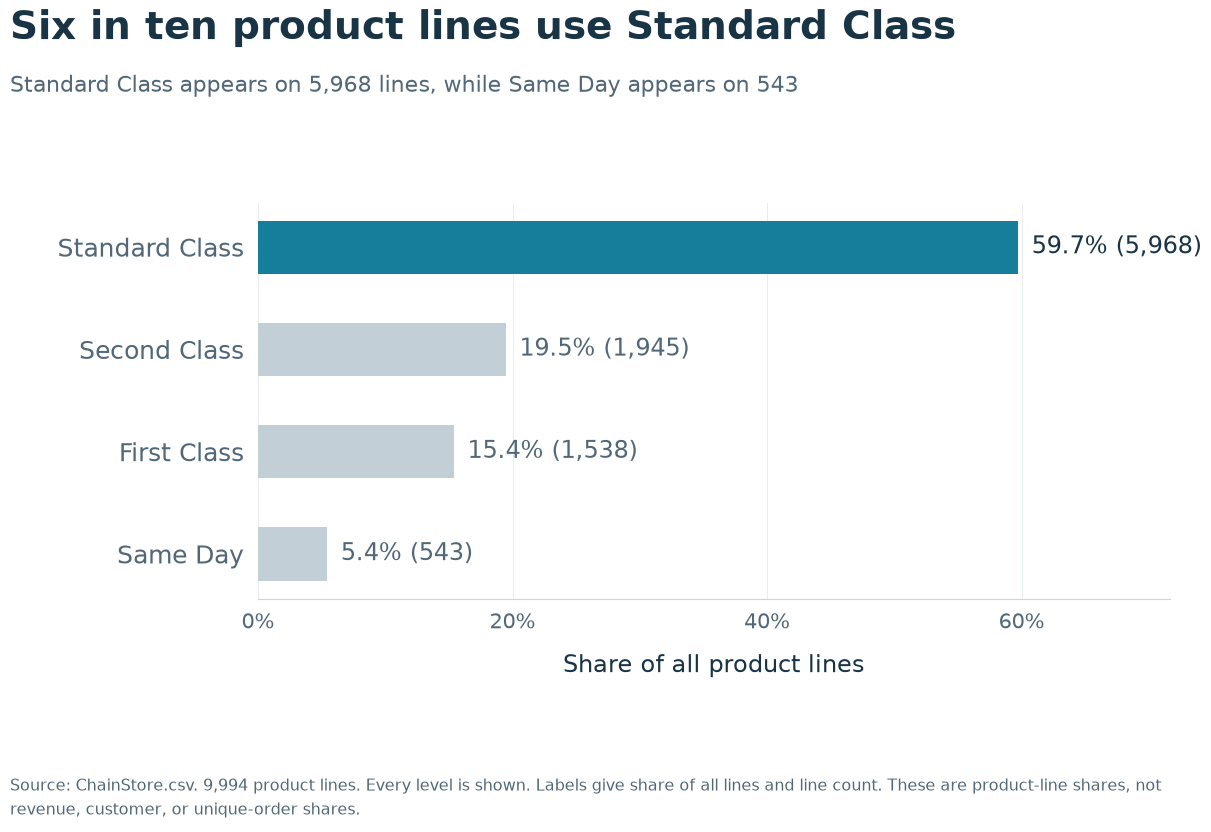

In [30]:
display(frequency_tables['Ship Mode'])
print('Distinct nonmissing categories:', data['Ship Mode'].nunique())
print('Missing values:', data['Ship Mode'].isna().sum())
print('Mode(s):', data['Ship Mode'].mode().tolist())
msds_plot_categorical(data['Ship Mode'])

## 4. Univariate Analysis Summary
Sales are strongly right-skewed: the mean is **$229.87** versus a **$54.50** median, with a maximum of **$22,638**. Profit is also right-skewed, with a **$28.65** mean and **$9.00** median, although both loss and gain extremes matter. **1,865 lines (18.66%)** have negative recorded profit. Quantity has a median and mode of **3 units**. Discount is concentrated at discrete levels: **0%** is the mode and **20%** the median. Profit Ratio has a pronounced negative tail: its mean is **12.05%**, median **27%**, and minimum **-275%**. Its mean is not the overall financial margin.

Office Supplies represent **60.30%** of lines. Binders are the largest Sub-Category (**15.24%**) and Copiers the smallest (**0.68%**). West is the largest Region (**32.05%**), Consumer the largest Segment (**51.94%**), and Standard Class the largest Ship Mode (**59.72%**). These are product-line shares, not revenue, unique-customer, or unique-order shares.

A typical product line is substantially smaller in Sales and Profit than the arithmetic means suggest. Medians and IQRs complement means and sample standard deviations in describing these tails. Categories show uneven representation. IQR flags identify unusual observations for review, not values to delete. Discrete quantities and discount levels require attention to their observed support.

Limitations include supplied whole-dollar and whole-percent precision, no detailed accounting dictionary or course helper files, one unresolved exact duplicate, and 11 missing postal codes outside the selected variables. No selected values require imputation and no rows are removed. These univariate results cannot establish causes or explain financial differences between categories. Line composition cannot be generalized to the wider US market without a sampling design. Only Part I is included.

## 6. Story

A a typical product line is small, Sales are concentrated in a minority of large lines, and positive averages coexist with frequent small profits and some substantial losses. These are descriptions of separate variables. The analysis does not establish why losses occur.

### 6.1. Sales concentration adds evidence to the average-versus-typical story

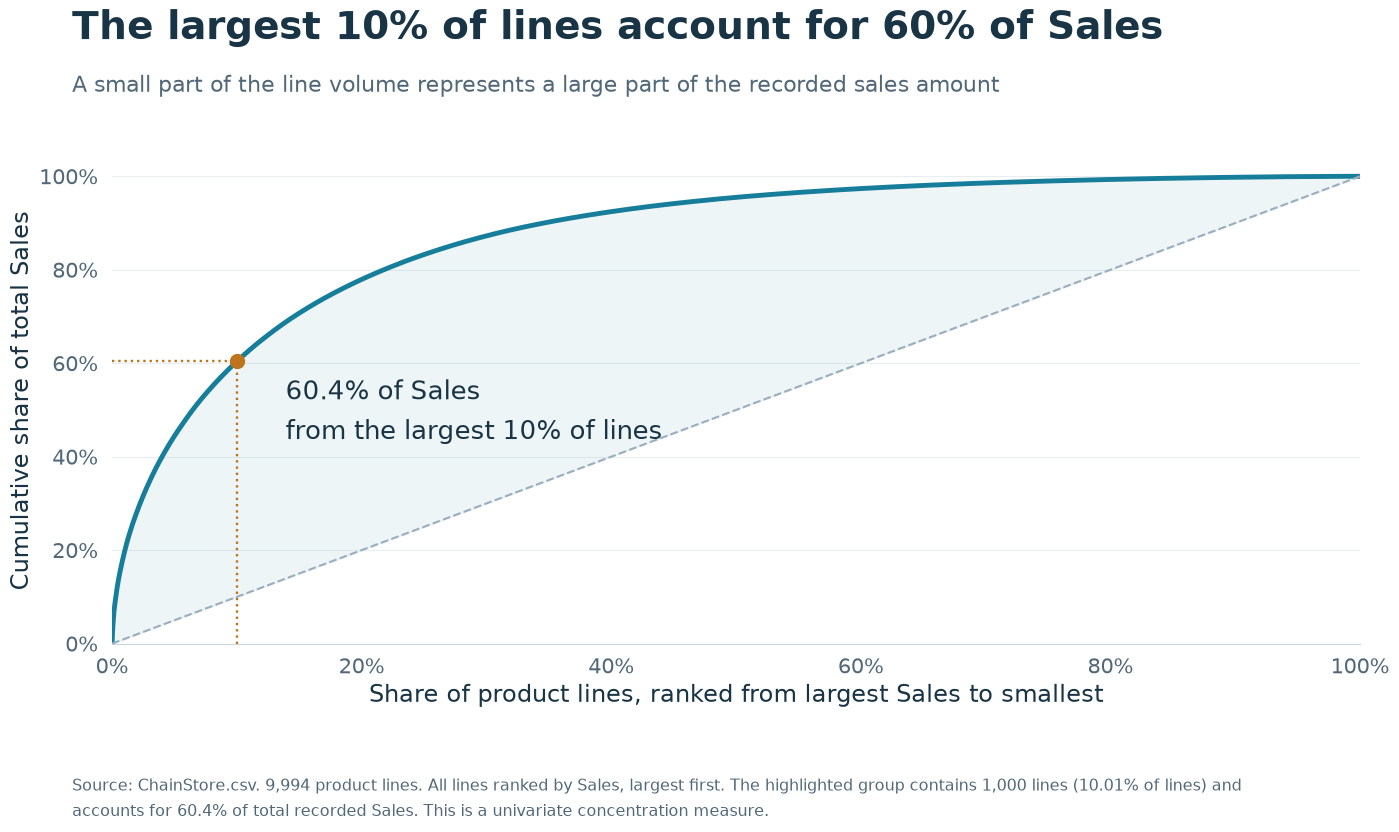

In [31]:
msds_plot_sales_concentration(data['Sales'])

### 6.2. Opening profile

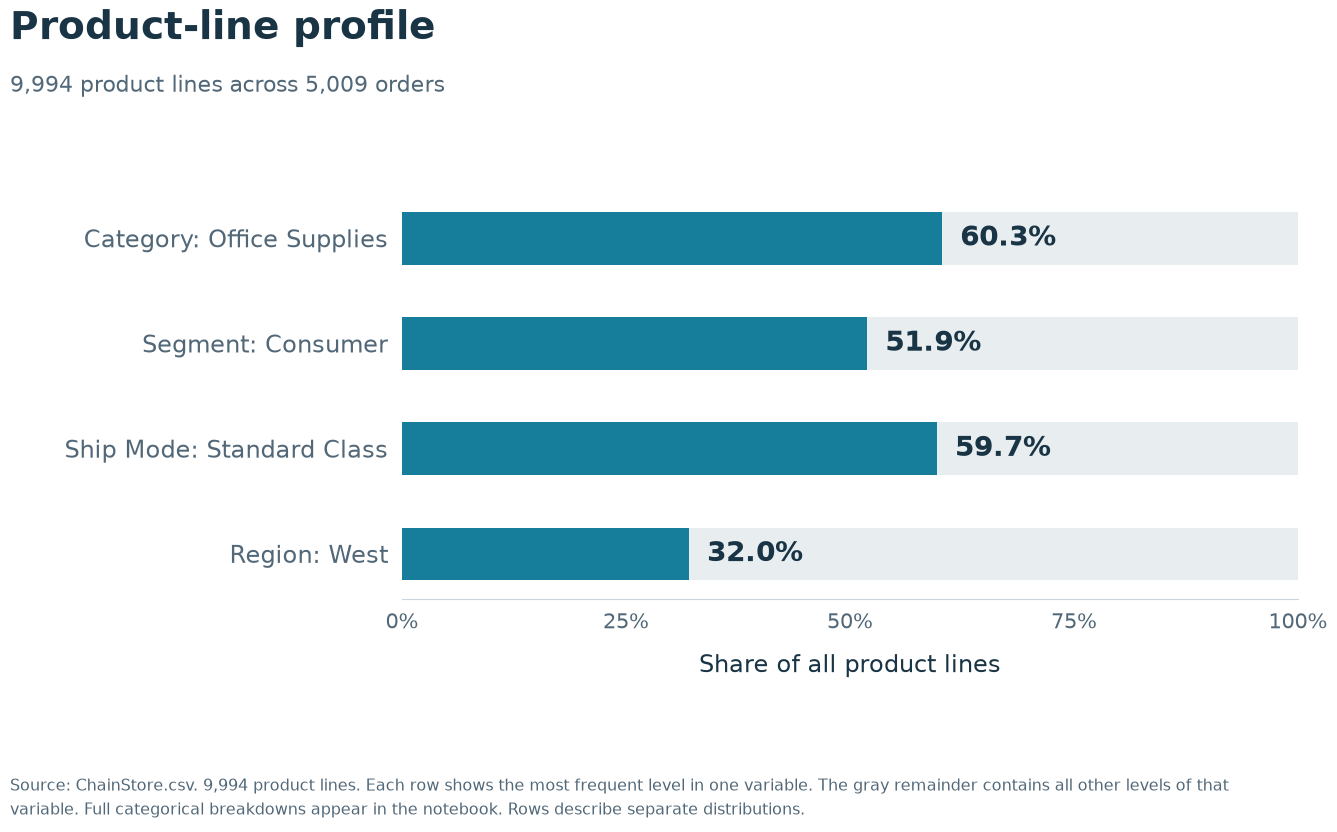

In [32]:
msds_plot_business_profile(data)

### 6.3. Technical

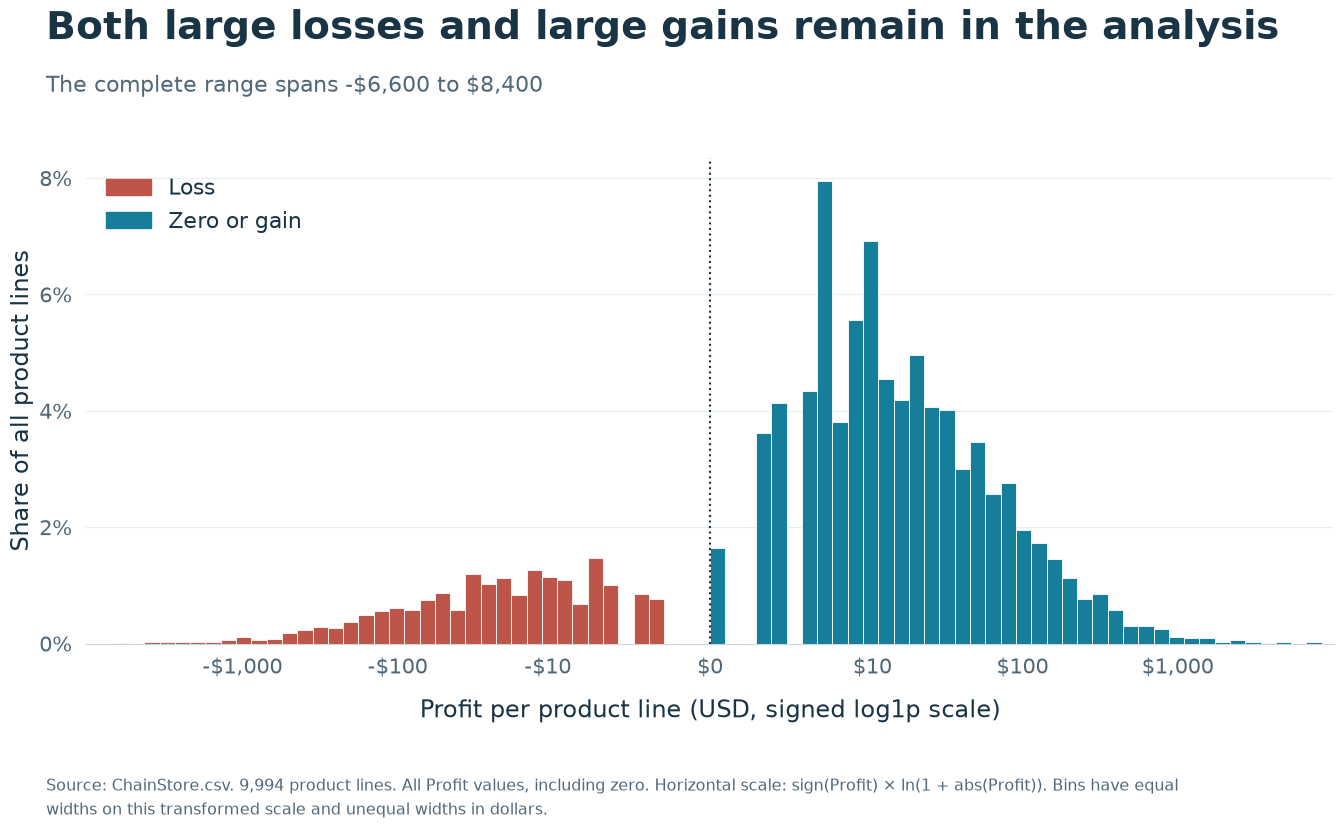

C:\Users\lucas\AppData\Local\Temp\ipykernel_46256\4053036517.py:382: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, whis=1.5, widths=0.45, patch_artist=True,
C:\Users\lucas\AppData\Local\Temp\ipykernel_46256\4053036517.py:382: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, whis=1.5, widths=0.45, patch_artist=True,
C:\Users\lucas\AppData\Local\Temp\ipykernel_46256\4053036517.py:382: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, whis=1.5, widths=0.45, patch_artist=True,
C:\Users\lucas\AppData\Local\Temp\ipykernel_46256\4053036517.py:382: MatplotlibDeprecationWarning

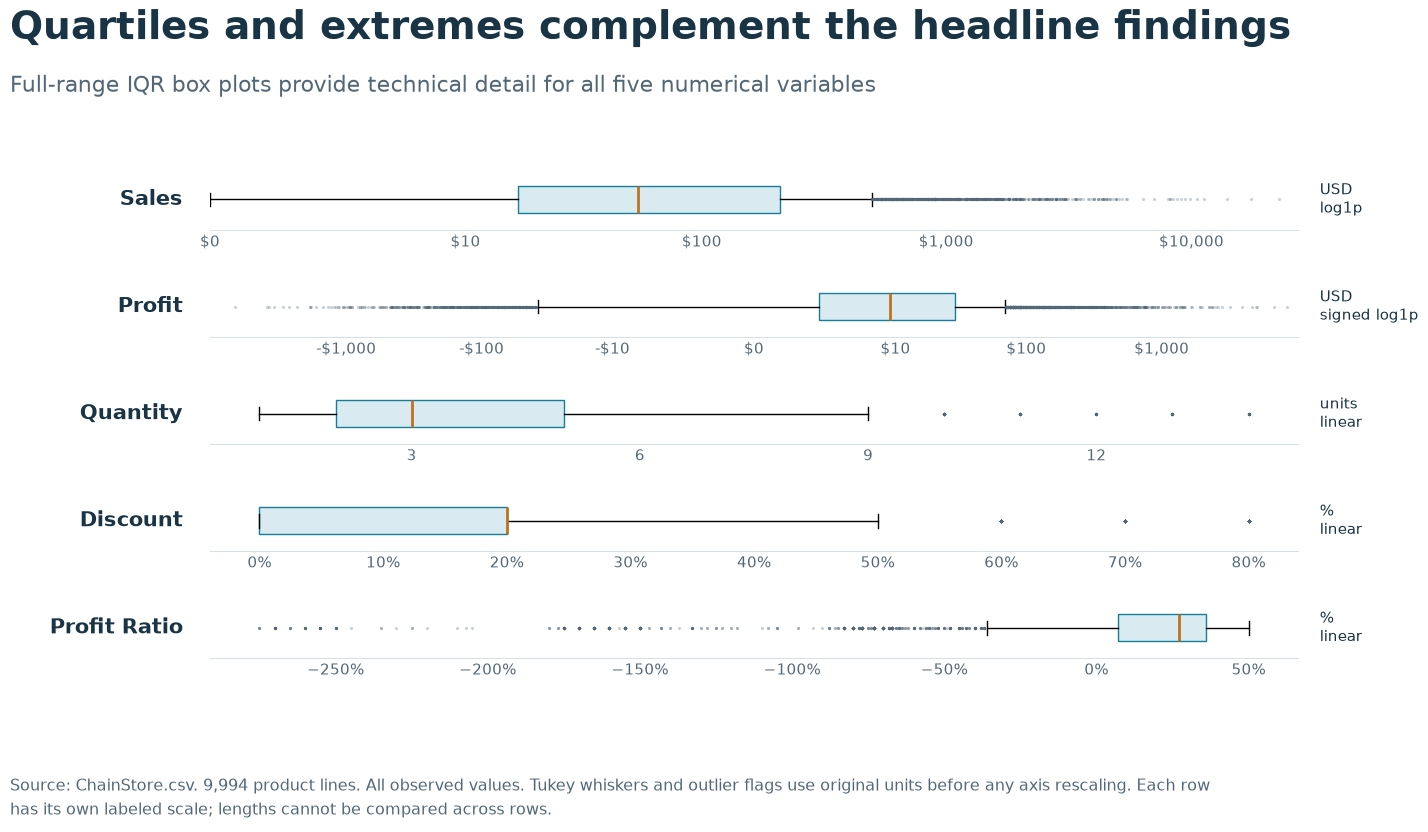

In [33]:
msds_plot_profit_full(data['Profit'])
msds_plot_boxplots(data)